# 04 · Termómetros por bloque (PCA causal por bloque)

Construye y valida los **termómetros por bloque**: una PCA causal pequeña por bloque temático del pool de
features (10 bloques en la pista B, 7 en la A), reajustada cada mes solo con el pasado y con el signo fijado
por una columna ancla, para que el termómetro suba con el estrés. Cada termómetro es una columna causal
nueva del panel y forma el **menú T** de los detectores ([ADR-008](../docs/decisions/ADR-008-preregistro-pool-termometros.md)).

Las secciones 1 a 9 solo usan pruebas **sin etiquetas de crisis** (`PendientesOscar.md` §6.5): con ellas se decide
el reparto en bloques, las anclas, el umbral de varianza y el calentamiento, y se validan los termómetros:

1. **Bien calculados**: factor plantado, prueba de prefijo, signo estable y NaN que no se propagan.
2. **Sentido estadístico y económico**: varianza de la PC1, peso máximo por columna, estabilidad de cargas
   y signos.
3. **Validez externa**: correlación con índices `rol=validation` (NFCI, OFR_FSI, STLFSI4, KCFSI, regla de
   Sahm, probabilidad de recesión…), que nunca entran como features.

Las secciones 10 y 11 cruzan los termómetros con las crisis, ya con el ADR-008 congelado: relevancia (punto 4) y
una primera prueba de valor añadido (punto 5). La significación (punto 6) queda pendiente.

> **Prueba de humo (30-10-2026).** Ejecutado en un portátil sin `data/processed`: los paneles se construyen
> **en memoria** con `regimenes.features.construir_paneles` (unos segundos) y **no se verifican contra los
> sha256** de `03_preprocesado`. Los crudos de esta máquina son una descarga anterior a ADR-003: faltan
> `SHILLER_SP500_CAPE` (`CAPE_z`) y las versiones multicolumna de `FF_5_INDUSTRY` y `FF_FACTORS_5_DAILY`
> (`FF_industry_dispersion_z`, `FF_RMW_z`). Esas 3 columnas quedan fuera, declaradas. Las cifras son
> orientativas; la versión oficial se ejecutará sobre los datos verificados.

**Índice**

1. Bloques y anclas (pre-registro)
2. Validación 1 · bien calculados (datos de juguete)
3. Paneles de las pistas en memoria
4. Por qué este reparto en bloques (pruebas sin etiquetas)
5. Umbral de varianza de la PC1
6. Calentamiento: historia anterior a la ventana
7. Termómetros de las dos pistas
8. Validación 2 · sentido estadístico y económico
9. Validación 3 · validez externa
10. Validación 4 · relevancia frente a las crisis
11. Valor añadido: menú N frente a menú T
12. Conclusiones y pendientes

In [1]:
import copy
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'font.size': 9,
                     'axes.spines.top': False, 'axes.spines.right': False})

from regimenes import rutas
from regimenes import features as ft
from regimenes.features import bloques as bq

pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)
PARAMS = bq.parametros_bloques()
BLOQUES = {p: bq.cargar_bloques(p) for p in ('A', 'B')}
print('Parámetros del pre-registro:', PARAMS)

Parámetros del pre-registro: {'reajuste': 'mensual', 'min_obs': 252, 'ventana': None, 'umbral_var': 0.3, 'umbrales_var_a_probar': [0.3, 0.4, 0.5], 'historia_previa': 'toda'}


## 1. Bloques y anclas (pre-registro)

El reparto sale de [`configs/bloques.yaml`](../configs/bloques.yaml), que congela el ADR-008. Cada columna
del pool está en un único bloque; la ancla es una columna del bloque con el signo con el que se espera que
suba con el estrés. La sección 4 explica por qué el reparto es este y no el de la propuesta inicial.

In [2]:
filas = []
for pista, bloques in BLOQUES.items():
    for nombre, b in bloques.items():
        filas.append({'pista': pista, 'termometro': nombre, 'n_columnas': len(b['columnas']),
                      'ancla': b['ancla']['columna'], 'signo': b['ancla']['signo'],
                      'columnas': ', '.join(b['columnas'])})
tabla_bloques = pd.DataFrame(filas)
display(tabla_bloques)
print(tabla_bloques.groupby('pista')['n_columnas'].agg(['count', 'sum']))

,pista,termometro,n_columnas,ancla,signo,columnas
0,A,T1_renta_variable,4,SP500_vol_z,1,"SP500_vol_z, SP500_momentum, SP500_drawdown, FF_industry_dispersion_z"
1,A,T1b_rentabilidad_diaria,3,SP500_ret_z,-1,"SP500_ret_z, FF_MKT_z, FF_MOM_z"
2,A,T2_tipos_nivel_curva,10,short_rate_z,1,"mid_curve_z, curve_vs_policy_10y_z, curve_vs_policy_5y_z, short_rate_z, TB3MS_z, GS1_z, GS5_z, GS10_z, term_spread_h..."
3,A,T3_velocidad_tipos,1,DGS10_change_z,1,DGS10_change_z
4,A,T6_credito,2,credit_BaaAaa_mensual_z,1,"credit_BaaAaa_mensual_z, credit_BaaFF_z"
5,A,T8_actividad,7,UNRATE_chg_z,1,"INDPRO_yoy_z, UNRATE_chg_z, PAYEMS_chg_z, UMCSENT_z, HOUST_yoy_z, MANEMP_yoy_z, GDP_growth_z"
6,A,T9_inflacion_valoracion,8,PPI_yoy_z,1,"CPI_yoy_z, CPI_core_yoy_z, PPI_yoy_z, PPI_fuels_yoy_z, PPI_metals_yoy_z, WTI_yoy_z, GW_valuation_z, CAPE_z"
7,B,T1_renta_variable,6,SP500_vol_z,1,"SP500_vol_z, SP500_momentum, SP500_drawdown, equity_breadth_dispersion_z, FF_industry_dispersion_z, sector_dispersion"
8,B,T1b_rentabilidad_diaria,8,SP500_ret_z,-1,"SP500_ret_z, FF_MKT_z, FF_MOM_z, FF_RMW_z, SP500_megacap_gap_z, smallcap_largecap_spread_z, style_spread_z, cyc_def_..."
9,B,T2_tipos_nivel_curva,15,short_rate_z,1,"slope_10y2y_z, slope_10y3m_z, curve_curvature_z, mid_curve_z, curve_vs_policy_10y_z, curve_vs_policy_5y_z, short_rat..."


       count  sum
pista            
A          7   35
B         10   77


## 2. Validación 1 · bien calculados (datos de juguete)

Las mismas comprobaciones que `tests/features/test_bloques.py`, a la vista:

- **Factor plantado.** Seis columnas = carga × factor + ruido; el termómetro debe recuperar el factor.
- **Prefijo.** Calcular con el panel truncado en `t` da exactamente lo mismo hasta `t` que calcular con todo
  y recortar, con cortes a mitad de mes.
- **Signo.** La carga de la ancla mantiene el signo declarado en todos los reajustes.
- **NaN.** Una columna que empieza tarde y un NaN puntual no hacen NaN al termómetro.

Correlación termómetro-factor: 0.869
Primer valor: 2001-01-01 | NaN tras el primer valor: 0
Signo de la ancla en todos los reajustes: True
Días renormalizados por NaN puntual: 1
Prueba de prefijo OK en 4 cortes (tolerancia 1e-10)


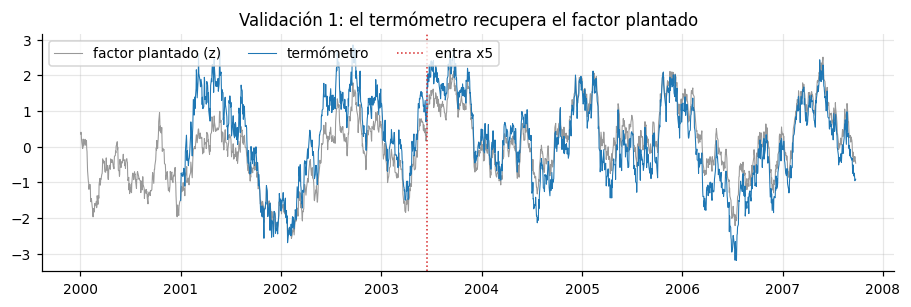

In [3]:
rng = np.random.default_rng(7)
idx = pd.bdate_range('2000-01-03', periods=252 * 8)
e = rng.normal(size=len(idx))
f = pd.Series(np.zeros(len(idx)), index=idx)
for i in range(1, len(idx)):
    f.iloc[i] = 0.98 * f.iloc[i - 1] + 0.2 * e[i]          # factor persistente y estacionario
cargas_plantadas = [1.0, 0.8, -0.6, 0.5, 0.9, -0.4]
juguete = pd.DataFrame({f'x{i}': c * f + rng.normal(scale=0.15, size=len(idx))
                        for i, c in enumerate(cargas_plantadas)}, index=idx)
juguete.loc[:idx[900], 'x5'] = np.nan          # columna que empieza tarde
juguete.loc[idx[1500], 'x1'] = np.nan          # NaN puntual
ancla = {'columna': 'x0', 'signo': 1}

t_jug, diag_jug = bq.termometro_bloque(juguete, list(juguete.columns), ancla, umbral_var=0.3)
validos = t_jug.dropna()
print(f'Correlación termómetro-factor: {validos.corr(f.loc[validos.index]):.3f}')
print('Primer valor:', validos.index[0].date(), '| NaN tras el primer valor:',
      int(t_jug.loc[validos.index[0]:].isna().sum()))
print('Signo de la ancla en todos los reajustes:',
      bool((diag_jug['carga_ancla'].dropna() > 0).all()))
print('Días renormalizados por NaN puntual:', int(diag_jug['n_dias_renormalizados'].fillna(0).sum()))

cortes = [idx[700], idx[1111], idx[1500], idx[-30]]
for corte in cortes:
    truncado, _ = bq.termometro_bloque(juguete.loc[:corte], list(juguete.columns), ancla, umbral_var=0.3)
    assert np.allclose(t_jug.loc[:corte].values, truncado.values, atol=1e-10, equal_nan=True)
print('Prueba de prefijo OK en', len(cortes), 'cortes (tolerancia 1e-10)')

fig, ax = plt.subplots(figsize=(10, 2.8))
ax.plot(f.index, (f - f.mean()) / f.std(), lw=.7, color='0.6', label='factor plantado (z)')
ax.plot(t_jug.index, t_jug, lw=.7, color='C0', label='termómetro')
ax.axvline(idx[900], color='C3', ls=':', lw=1, label='entra x5')
ax.legend(loc='upper left', ncol=3); ax.set_title('Validación 1: el termómetro recupera el factor plantado')
plt.show()

## 3. Paneles de las pistas en memoria

Mismas series (`benchmark_spec.yaml`) y la misma función que `03_preprocesado`, sin escribir a disco. Se
construyen dos versiones de cada panel: la de la **ventana** del benchmark y la **extendida** con toda la
historia anterior disponible (sección 6). El termómetro se calcula sobre la unión de los paneles diario y
mensual (sin las columnas `*_edad_dias`, que son metadatos).

In [4]:
cov = pd.read_csv(rutas.DATA_RAW / 'coverage_report.csv')
SRC = dict(zip(cov.nombre, cov.fuente))
BENCH = yaml.safe_load(rutas.BENCHMARK_SPEC.read_text(encoding='utf-8'))
INICIO = {p: pd.Timestamp(BENCH[f'pista_{p}']['ventana_inicio']) for p in ('A', 'B')}


def carga(nombres):
    crudo, faltan = {}, []
    for n in nombres:
        try:
            crudo[n] = ft.seleccionar_raw(pd.read_parquet(rutas.DATA_RAW / SRC[n] / f'{n}.parquet'), n)
        except Exception:
            faltan.append(n)
    return crudo, faltan


CRUDO = {}
def panel_pista(pista, inicio=None):
    b = BENCH[f'pista_{pista}']
    if pista not in CRUDO:
        CRUDO[pista] = carga(b['series_features'])
    p = ft.construir_paneles(CRUDO[pista][0], str(inicio or b['ventana_inicio']), b['ventana_fin'])
    mensual = p['mensual'][[c for c in p['mensual'].columns if not c.endswith('_edad_dias')]]
    return p['diaria'].join(mensual)


PANEL, PANEL_EXT = {}, {}
for pista in ('A', 'B'):
    PANEL[pista] = panel_pista(pista)
    PANEL_EXT[pista] = panel_pista(pista, inicio='1900-01-01')   # toda la historia de la rejilla
    pool = [c for b in BLOQUES[pista].values() for c in b['columnas']]
    print(f'Pista {pista}: ventana {PANEL[pista].shape} desde {PANEL[pista].index[0].date()} | '
          f'extendido desde {PANEL_EXT[pista].index[0].date()} | pool {len(pool)} | '
          f'en panel {len(set(pool) & set(PANEL[pista].columns))} | series que faltan {CRUDO[pista][1]} | '
          f'sin construir {sorted(set(pool) - set(PANEL[pista].columns))}')

Pista A: ventana (16210, 33) desde 1962-01-02 | extendido desde 1927-12-30 | pool 35 | en panel 33 | series que faltan ['SHILLER_SP500_CAPE'] | sin construir ['CAPE_z', 'FF_industry_dispersion_z']


Pista B: ventana (4815, 74) desde 2007-04-11 | extendido desde 1927-12-30 | pool 77 | en panel 74 | series que faltan ['SHILLER_SP500_CAPE'] | sin construir ['CAPE_z', 'FF_RMW_z', 'FF_industry_dispersion_z']


## 4. Por qué este reparto en bloques (pruebas sin etiquetas)

La propuesta inicial (`PendientesOscar.md` §6.3) tenía 8 bloques en B y 5 en A. Dos bloques no funcionaban:

- **T1 · renta variable** mezclaba columnas de **estado** (volatilidad, drawdown, momentum, dispersiones),
  que son persistentes, con **rentabilidades diarias** (S&P 500, factores Fama-French, spreads de estilo),
  que no tienen memoria: lo que pasó hoy no dice nada de mañana. La PCA busca lo que las columnas tienen
  en común, y estos dos grupos apenas se correlacionan entre sí (una rentabilidad diaria con el nivel de la
  volatilidad ≈ 0), así que la PC1 se queda en tierra de nadie y explica poco. Además, cuando cae a la media,
  cada columna se orienta por el signo de su correlación con la ancla, que es ≈ 0: el signo sale al azar.
- **T8 · macro y valoración** mezclaba actividad (paro, empleo, producción) con inflación realizada y
  valoración. En la pista A, de 1962 a 1985 lo que más varía es la inflación, así que la PC1 es inflación
  y la ancla (el paro) carga poco: el signo salta.

### 4.1 Memoria de las columnas

Autocorrelación a un día (≈ 0 = ruido diario; ≈ 1 = estado persistente) y correlación con la ancla.

In [5]:
for pista in ('B', 'A'):
    b = BLOQUES[pista]
    t1b = b['T1b_rentabilidad_diaria']['columnas']
    cols = [c for c in b['T1_renta_variable']['columnas'] + t1b if c in PANEL[pista]]
    X = PANEL[pista][cols]
    memoria = pd.DataFrame({'autocorr_1d': X.apply(lambda s: s.dropna().autocorr(1)),
                            'corr_con_SP500_vol_z': X.corr()['SP500_vol_z'],
                            'bloque_final': ['T1b' if c in t1b else 'T1' for c in cols]})
    print(f'Pista {pista}: T1 + T1b de la propuesta inicial')
    display(memoria.sort_values('autocorr_1d').round(2))

Pista B: T1 + T1b de la propuesta inicial


,autocorr_1d,corr_con_SP500_vol_z,bloque_final
SP500_ret_z,-0.12,-0.01,T1b
FF_MKT_z,-0.11,0.00,T1b
smallcap_largecap_spread_z,-0.04,-0.01,T1b
style_spread_z,-0.01,0.01,T1b
cyc_def_ratio_z,-0.00,-0.01,T1b
SP500_megacap_gap_z,0.01,0.01,T1b
FF_MOM_z,0.09,-0.02,T1b
equity_breadth_dispersion_z,0.37,0.38,T1
sector_dispersion,0.54,0.56,T1
SP500_momentum,0.99,-0.50,T1


Pista A: T1 + T1b de la propuesta inicial


,autocorr_1d,corr_con_SP500_vol_z,bloque_final
SP500_ret_z,-0.02,-0.00,T1b
FF_MKT_z,0.02,0.00,T1b
FF_MOM_z,0.17,-0.03,T1b
SP500_vol_z,0.99,1.00,T1
SP500_momentum,1.00,-0.31,T1
SP500_drawdown,1.00,-0.46,T1


### 4.2 Variantes comparadas

Para cada variante se mide, sin crisis: la varianza mediana de la PC1, la fracción de reajustes con PCA
(umbral 30 %), los saltos de signo y la correlación máxima con sus índices de validación de referencia
(T1 con STLFSI4, NFCI_RISK, OFR_FSI_VOLATILITY y el VIX; T8 con la regla de Sahm, la probabilidad de recesión
suavizada y las recesiones NBER).

- **inicial**: la propuesta de §6.3 (T1 = T1 ∪ T1b; T8 = T8 ∪ T9, ancla paro).
- **T1 sin rentabilidades**: se quitan las rentabilidades diarias de T1 y se descartan (pierde pool).
- **final**: T1/T1b separados; T8 actividad y T9 inflación realizada + valoración (ancla PPI).
- **final, T9 con ancla CPI** y **final, valoración en T8**: alternativas de la decisión final.
- **B: inflación realizada en T4**: en vez de un T9 propio, la inflación realizada junto a las expectativas.

In [6]:
REFS = {'T1': ['STLFSI4', 'NFCI_RISK', 'OFR_FSI_VOLATILITY', 'VIX_VALIDATION_REF'],
        'T8': ['SAHM_RULE_REALTIME', 'RECESSION_PROB_SMOOTHED', 'NBER_RECESSION_DAILY']}
VALIDACION, _ = carga(sorted({v for vs in REFS.values() for v in vs} |
                             {'NFCI', 'ANFCI', 'NFCI_CREDIT', 'NFCI_LEVERAGE', 'OFR_FSI', 'OFR_FSI_CREDIT',
                              'OFR_FSI_FUNDING', 'KCFSI'}))


def alinear(s, index):
    s = s.squeeze() if isinstance(s, pd.DataFrame) else s
    return s.sort_index().reindex(s.index.union(index)).ffill().reindex(index)


def fusiona(bl, a, b, nombre, ancla):
    bl = copy.deepcopy(bl)
    x, y = bl.pop(a), bl.pop(b)
    bl[nombre] = {'columnas': x['columnas'] + y['columnas'], 'ancla': ancla}
    return bl


def variantes(pista):
    fin = BLOQUES[pista]
    ini = fusiona(fin, 'T1_renta_variable', 'T1b_rentabilidad_diaria', 'T1_renta_variable',
                  fin['T1_renta_variable']['ancla'])
    ini = fusiona(ini, 'T8_actividad', 'T9_inflacion_valoracion', 'T8_macro_valoracion',
                  fin['T8_actividad']['ancla'])
    sin_ret = fusiona(fin, 'T8_actividad', 'T9_inflacion_valoracion', 'T8_macro_valoracion',
                      fin['T8_actividad']['ancla'])
    sin_ret.pop('T1b_rentabilidad_diaria')
    cpi = copy.deepcopy(fin); cpi['T9_inflacion_valoracion']['ancla'] = {'columna': 'CPI_yoy_z', 'signo': 1}
    val = copy.deepcopy(fin)
    v = [c for c in val['T9_inflacion_valoracion']['columnas'] if c in ('GW_valuation_z', 'CAPE_z')]
    val['T9_inflacion_valoracion']['columnas'] = [c for c in val['T9_inflacion_valoracion']['columnas'] if c not in v]
    val['T8_actividad']['columnas'] += v
    out = {'inicial': ini, 'T1 sin rentabilidades': sin_ret, 'final': fin,
           'final, T9 con ancla CPI': cpi, 'final, valoración en T8': val}
    if pista == 'B':
        t4 = copy.deepcopy(fin)
        inf = [c for c in t4['T9_inflacion_valoracion']['columnas'] if c not in ('GW_valuation_z', 'CAPE_z')]
        t4['T4_inflacion_tipo_real']['columnas'] += inf
        t4['T8_actividad']['columnas'] += ['GW_valuation_z', 'CAPE_z']
        t4.pop('T9_inflacion_valoracion')
        out['B: inflación realizada en T4'] = t4
    return out


def evalua(panel, bloques, umbral=0.30, recorte=None):
    T, D = bq.construir_termometros(panel, bloques, umbral_var=umbral, min_obs=PARAMS['min_obs'])
    if recorte is not None:
        T = T.loc[recorte:]
    R = bq.resumen_estabilidad(T, D).set_index('termometro')
    V = pd.DataFrame({n: alinear(s, T.index) for n, s in VALIDACION.items()})
    filas = []
    for t in T.columns:
        refs = REFS.get(t.split('_')[0], [])
        rho = [T[t].corr(V[v]) for v in refs]
        filas.append({'termometro': t, 'n_cols': len(bloques[t]['columnas']),
                      'var_pc1': R.loc[t, 'var_pc1_mediana'], 'frac_pca': R.loc[t, 'frac_pca'],
                      'cambios_metodo': R.loc[t, 'n_cambios_metodo'], 'saltos_signo': R.loc[t, 'n_saltos_signo'],
                      'rho_ext_max': max(rho) if rho else np.nan})
    return pd.DataFrame(filas).set_index('termometro'), T, D


comparativa = []
for pista in ('B', 'A'):
    for nombre, bl in variantes(pista).items():
        tab, _, _ = evalua(PANEL[pista], bl)
        tab = tab.loc[[i for i in tab.index if i.startswith(('T1', 'T4', 'T8', 'T9'))]]
        comparativa.append(tab.assign(pista=pista, variante=nombre).reset_index())
comparativa = pd.concat(comparativa, ignore_index=True)
display(comparativa.set_index(['pista', 'variante', 'termometro']).round(3))

n_cols  var_pc1  frac_pca  cambios_metodo  saltos_signo  rho_ext_max
pista variante                     termometro                                                                                   
B     inicial                      T4_inflacion_tipo_real        4    0.680     1.000               0             0          NaN
                                   T1_renta_variable            14    0.288     0.312               4             2        0.577
                                   T8_macro_valoracion          18    0.445     1.000               0             0        0.768
      T1 sin rentabilidades        T1_renta_variable             6    0.624     1.000               0             0        0.776
                                   T4_inflacion_tipo_real        4    0.680     1.000               0             0          NaN
                                   T8_macro_valoracion          18    0.445     1.000               0             0        0.768
      final                        T1_renta_variable             6    0.624     1.000               0             0        0.776
                                   T1b_rentabilidad_diaria       8    0.489     1.000               0             0          NaN
                                   T4_inflacion_tipo_real        4    0.680     1.000               0             0          NaN
                                   T8_actividad                 11    0.647     1.000               0             0        0.763
                                   T9_inflacion_valoracion       7    0.571     1.000               0             0          NaN
      final, T9 con ancla CPI      T1_renta_variable             6    0.624     1.000               0             0        0.776
                                   T1b_rentabilidad_diaria       8    0.489     1.000               0             0          NaN
                                   T4_inflacion_tipo_real        4    0.680     1.000               0             0          NaN
                                   T8_actividad                 11    0.647     1.000               0             0        0.763
                                   T9_inflacion_valoracion       7    0.571     1.000               0             0          NaN
      final, valoración en T8      T1_renta_variable             6    0.624     1.000               0             0        0.776
                                   T1b_rentabilidad_diaria       8    0.489     1.000               0             0          NaN
                                   T4_inflacion_tipo_real        4    0.680     1.000               0             0          NaN
                                   T8_actividad                 13    0.601     1.000               0             0        0.768
                                   T9_inflacion_valoracion       5    0.640     1.000               0             0          NaN
      B: inflación realizada en T4 T1_renta_variable             6    0.624     1.000               0             0        0.776
                                   T1b_rentabilidad_diaria       8    0.489     1.000               0             0          NaN
                                   T4_inflacion_tipo_real        9    0.426     1.000               0             3          NaN
                                   T8_actividad                 13    0.601     1.000               0             0        0.768
A     inicial                      T1_renta_variable             7    0.341     1.000               0             1        0.413
                                   T8_macro_valoracion          15    0.431     1.000               0             4        0.510
      T1 sin rentabilidades        T1_renta_variable             4    0.654     1.000               0             0        0.807
                                   T8_macro_valoracion          15    0.431     1.000               0             4        0.510
      final                        T1_renta_variable         

**Decisión (sin etiquetas).** Gana **final**:

- Separar las rentabilidades sube la PC1 de T1 de ~0,29 a ~0,62 (B) y de ~0,34 a ~0,65 (A), elimina los
  saltos de signo y sube su validez externa de ~0,58 a ~0,78 (B) y de ~0,41 a ~0,81 (A). Se **separan** en
  T1b en vez de quitarlas, para no perder pool: los modelos de estados (HMM, GMM) necesitan una señal de
  rentabilidad, y T1b es el factor de mercado diario (cae = estrés).
- Separar la inflación de la actividad deja T8 sin saltos de signo y sube su correlación con la regla de
  Sahm de ~0,51 a ~0,75 en A.
- Ancla PPI en T9: menos saltos de signo que con CPI. Valoración junto a la inflación: T8 queda más limpio.
- En B, la inflación realizada no va con las expectativas (T4): la PC1 de T4 cae y aparecen saltos de signo.

### 4.3 Ancla de T2 (tipos: nivel y curva)

La PC1 de T2 es el **nivel de tipos**: carga positiva en los tipos y negativa en las pendientes. La ancla
solo fija el signo, pero si carga poco puede quedar cerca de cero en algún reajuste y el signo salta. Se
comparan anclas por saltos de signo dentro de la ventana y por su carga mediana.

In [7]:
filas = []
for pista in ('A', 'B'):
    cols = BLOQUES[pista]['T2_tipos_nivel_curva']['columnas']
    for col, signo in [('term_spread_hist_z', -1), ('slope_10y3m_z', -1), ('short_rate_z', 1),
                       ('GS1_z', 1), ('fed_stance_z', 1)]:
        if col not in cols:
            continue
        b = {'T2': {'columnas': cols, 'ancla': {'columna': col, 'signo': signo}}}
        _, D = bq.construir_termometros(PANEL_EXT[pista], b, umbral_var=PARAMS['umbral_var'])
        d = D['T2'][D['T2']['fecha_reajuste'] >= INICIO[pista]]
        filas.append({'pista': pista, 'ancla': f'{signo:+d} · {col}',
                      'saltos_signo': int((d['coseno_prev'] < 0).sum()),
                      'carga_ancla_mediana': d['carga_ancla'].abs().median()})
display(pd.DataFrame(filas).round(3))
print('Ancla decidida:', {p: BLOQUES[p]['T2_tipos_nivel_curva']['ancla'] for p in ('A', 'B')})

,pista,ancla,saltos_signo,carga_ancla_mediana
0,A,-1 · term_spread_hist_z,2,0.275
1,A,+1 · short_rate_z,0,0.377
2,A,+1 · GS1_z,0,0.371
3,A,+1 · fed_stance_z,6,0.191
4,B,-1 · term_spread_hist_z,0,0.268
5,B,-1 · slope_10y3m_z,0,0.274
6,B,+1 · short_rate_z,0,0.293
7,B,+1 · GS1_z,0,0.292
8,B,+1 · fed_stance_z,0,0.248


Ancla decidida: {'A': {'columna': 'short_rate_z', 'signo': 1}, 'B': {'columna': 'short_rate_z', 'signo': 1}}


**Decisión: `short_rate_z` (+1) en las dos pistas.** Es la columna que más carga y no da saltos de
signo; la pendiente daba 2 saltos en A (1963) y `fed_stance_z` 6. El termómetro sigue significando «tipos
altos y curva plana o invertida»: cambia la robustez, no el sentido.

## 5. Umbral de varianza de la PC1

Si en un reajuste la PC1 explica menos que el umbral, ese tramo usa la media simple de las columnas
orientadas. Se prueba la rejilla acordada (30, 40 y 50 %) y dos extremos de control: 0 (siempre PCA) y
1,01 (siempre media). Criterio, sin crisis: menos **cambios de método** (cada alternancia PCA ↔ media puede
meter un escalón) y **saltos de signo**, sin perder validez externa.

In [8]:
filas = []
for pista in ('B', 'A'):
    base = None
    for u in (0.0, 0.30, 0.40, 0.50, 1.01):
        tab, T, _ = evalua(PANEL[pista], BLOQUES[pista], umbral=u)
        base = T if base is None else base
        filas.append({'pista': pista, 'umbral': u, 'frac_pca_media': tab['frac_pca'].mean(),
                      'cambios_metodo': tab['cambios_metodo'].sum(), 'saltos_signo': tab['saltos_signo'].sum(),
                      'rho_ext_T1': tab.loc['T1_renta_variable', 'rho_ext_max'],
                      'rho_ext_T8': tab.loc['T8_actividad', 'rho_ext_max'],
                      'corr_con_siempre_PCA': np.nanmean([T[c].corr(base[c]) for c in T])})
umbrales = pd.DataFrame(filas)
display(umbrales.round(3))
minimos = {p: {k: round(d.loc[d['metodo'] == 'pca', 'var_pc1'].min(), 2)
               for k, d in evalua(PANEL[p], BLOQUES[p], umbral=0.0)[2].items() if (d['metodo'] == 'pca').any()}
           for p in ('B', 'A')}
print('Varianza mínima de la PC1 por termómetro (siempre PCA):', minimos)
print('Umbral decidido (configs/bloques.yaml):', PARAMS['umbral_var'])

,pista,umbral,frac_pca_media,cambios_metodo,saltos_signo,rho_ext_T1,rho_ext_T8,corr_con_siempre_PCA
0,B,0.00,1.000,0,0,0.776,0.763,1.000
1,B,0.30,1.000,0,0,0.776,0.763,1.000
2,B,0.40,0.849,7,0,0.776,0.763,0.987
3,B,0.50,0.703,4,0,0.776,0.752,0.983
4,B,1.01,0.000,0,0,0.764,0.741,0.968
5,A,0.00,1.000,0,1,0.807,0.752,1.000
6,A,0.30,1.000,0,1,0.807,0.752,1.000
7,A,0.40,0.998,4,0,0.807,0.752,1.000
8,A,0.50,0.991,8,0,0.807,0.752,1.000
9,A,1.01,0.000,0,0,0.823,0.722,0.985


Varianza mínima de la PC1 por termómetro (siempre PCA): {'B': {'T1_renta_variable': np.float64(0.55), 'T1b_rentabilidad_diaria': np.float64(0.4), 'T2_tipos_nivel_curva': np.float64(0.62), 'T3_velocidad_tipos': np.float64(0.59), 'T4_inflacion_tipo_real': np.float64(0.48), 'T5_vol_implicita': np.float64(0.37), 'T6_credito': np.float64(0.54), 'T7_divisas_materias_primas': np.float64(0.3), 'T8_actividad': np.float64(0.45), 'T9_inflacion_valoracion': np.float64(0.53)}, 'A': {'T1_renta_variable': np.float64(0.59), 'T1b_rentabilidad_diaria': np.float64(0.66), 'T2_tipos_nivel_curva': np.float64(0.33), 'T6_credito': np.float64(0.51), 'T8_actividad': np.float64(0.41), 'T9_inflacion_valoracion': np.float64(0.39)}}
Umbral decidido (configs/bloques.yaml): 0.3


**Decisión: 30 %.** Con el reparto final la PC1 nunca baja de 0,30 en ningún termómetro, así que el
umbral del 30 % no se activa y da lo mismo que «siempre PCA», sin cambios de método. A 40 y 50 % aparecen
cambios PCA ↔ media sin ganar validez externa. Se queda el 30 % y no el 0 porque es una **red de seguridad**:
si en los datos oficiales un bloque perdiese estructura común, pasaría a la media en vez de dar una PC1
débil. Vigilar T7 en B, cuyo mínimo está justo en 0,30.

## 6. Calentamiento: historia anterior a la ventana

Con `min_obs = 252` el termómetro necesita un año de datos antes de dar valor. Si se calcula solo dentro de
la ventana, la pista B no tiene termómetros hasta mayo de 2008, y el entrenamiento de los detectores del
menú T arrancaría un año más tarde que el del menú N. La alternativa es causal: calcular con la historia
anterior a `ventana_inicio` (la que ya usan los z-scores) y recortar. Se compara cuánta historia hace falta:
días de la ventana sin termómetro y parecido con la versión de toda la historia (en los dos primeros años de
la ventana y en total).

In [9]:
filas = []
for pista in ('B', 'A'):
    _, ref, _ = evalua(PANEL_EXT[pista], BLOQUES[pista], recorte=INICIO[pista])
    for anios in (0, 1, 2, 3, 5):
        p = PANEL_EXT[pista].loc[INICIO[pista] - pd.DateOffset(years=anios):]
        _, T, _ = evalua(p, BLOQUES[pista], recorte=INICIO[pista])
        tramo = T.loc[:INICIO[pista] + pd.DateOffset(years=2)].index
        filas.append({'pista': pista, 'años_previos': anios,
                      'dias_ventana_sin_valor': int(T.isna().any(axis=1).sum()),
                      'corr_con_toda_primeros_2a': np.nanmean([T.loc[tramo, c].corr(ref.loc[tramo, c]) for c in T]),
                      'corr_con_toda_total': np.nanmean([T[c].corr(ref[c]) for c in T])})
display(pd.DataFrame(filas).round(3))
print('Calentamiento decidido (configs/bloques.yaml): historia_previa =', PARAMS['historia_previa'])

,pista,años_previos,dias_ventana_sin_valor,corr_con_toda_primeros_2a,corr_con_toda_total
0,B,0,267,0.880,0.966
1,B,1,14,0.833,0.949
2,B,2,0,0.897,0.953
3,B,3,0,0.930,0.963
4,B,5,0,0.993,0.993
5,A,0,252,0.741,0.988
6,A,1,61,0.916,0.983
7,A,2,61,0.836,0.988
8,A,3,61,0.753,0.987
9,A,5,61,0.994,0.991


Calentamiento decidido (configs/bloques.yaml): historia_previa = toda


**Decisión: toda la historia disponible.** Sin historia previa, B pierde más de un año de
termómetros. Con 1 año aún faltan días; con 2–3 años no faltan, pero los primeros reajustes se parecen menos
a la versión estable. Con 5 años ya coincide prácticamente con la de toda la historia. La regla más simple y
estable es usar toda la historia, igual que los z-scores: no mira el futuro, solo el pasado anterior a la
ventana. Las cifras exactas, en la tabla.

## 7. Termómetros de las dos pistas

Reparto final, umbral del 30 % y toda la historia previa, recortados a la ventana de cada pista. Las
figuras no llevan franjas de crisis a propósito: esta validación no usa etiquetas.

Pista A: 7 termómetros; días de la ventana sin valor: 61


Pista B: 10 termómetros; días de la ventana sin valor: 0


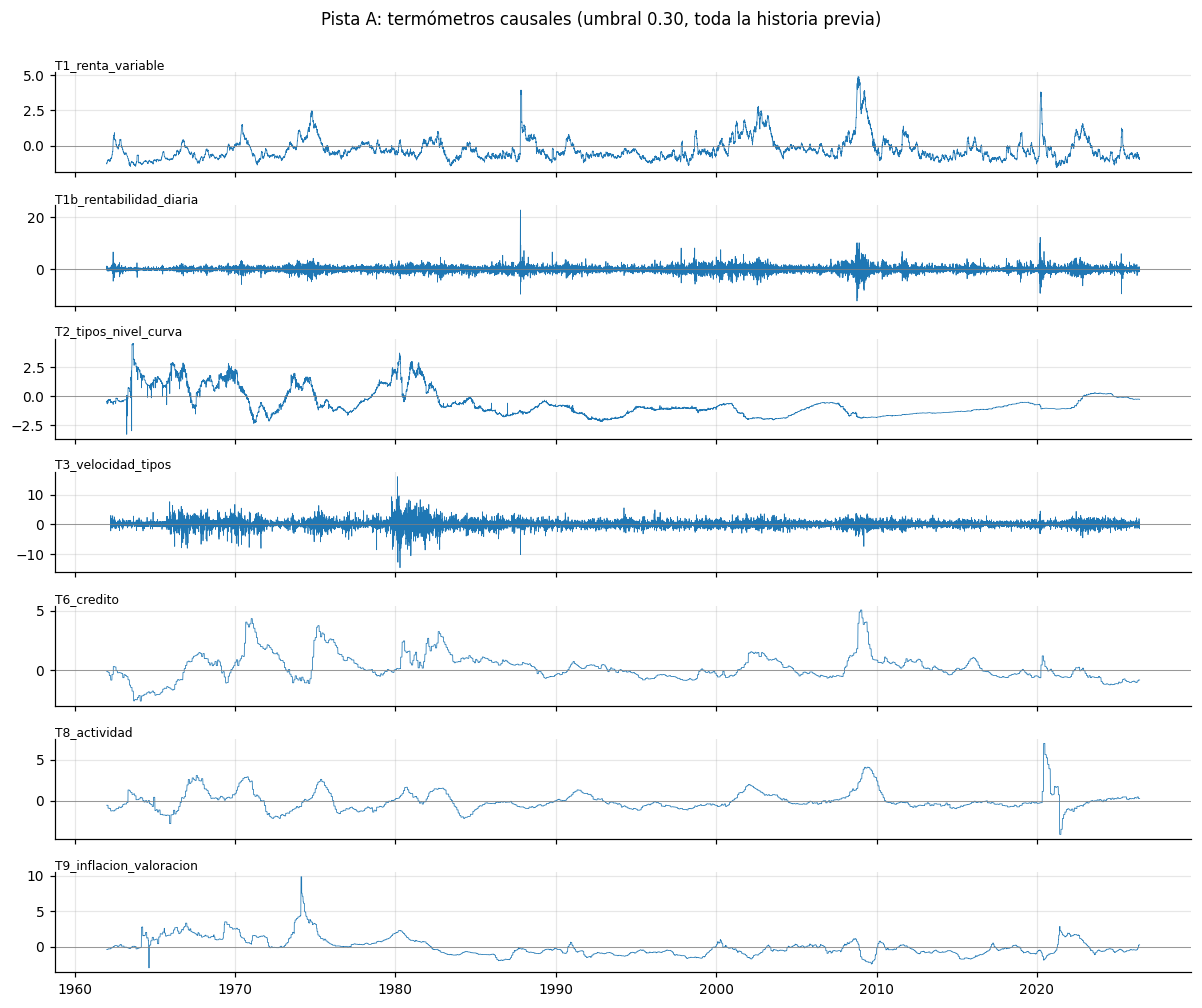

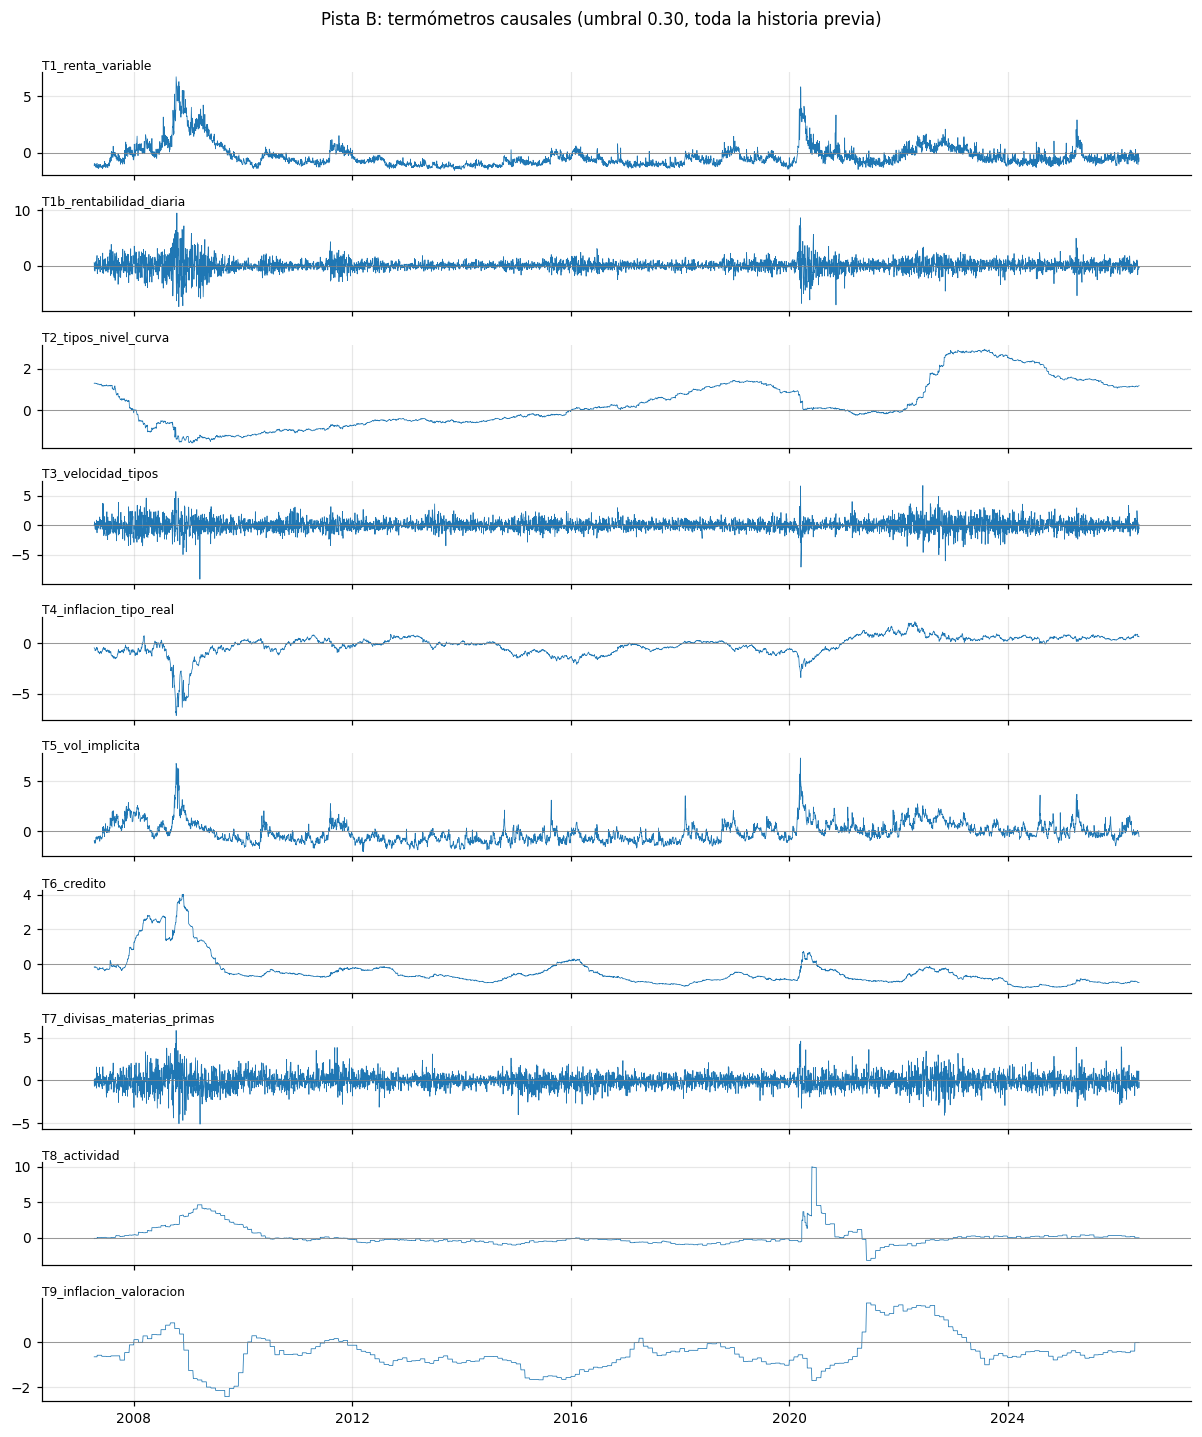

In [10]:
TERM, DIAG = {}, {}
for pista in ('A', 'B'):
    T, D = bq.construir_termometros(PANEL_EXT[pista], BLOQUES[pista], umbral_var=PARAMS['umbral_var'],
                                    min_obs=PARAMS['min_obs'])
    TERM[pista] = T.loc[INICIO[pista]:]
    DIAG[pista] = D
    print(f'Pista {pista}: {T.shape[1]} termómetros; días de la ventana sin valor: '
          f'{int(TERM[pista].isna().any(axis=1).sum())}')

for pista in ('A', 'B'):
    T = TERM[pista]
    fig, axes = plt.subplots(len(T.columns), 1, figsize=(11, 1.3 * len(T.columns)), sharex=True)
    for ax, c in zip(np.atleast_1d(axes), T.columns):
        ax.plot(T.index, T[c], lw=.5, color='C0')
        ax.axhline(0, color='0.5', lw=.5)
        ax.set_title(c, fontsize=8, loc='left', pad=2)
    fig.suptitle(f'Pista {pista}: termómetros causales (umbral {PARAMS["umbral_var"]:.2f}, toda la historia previa)', y=1.0)
    plt.tight_layout(); plt.show()

## 8. Validación 2 · sentido estadístico y económico

Criterios propuestos en el ADR-008 §5, sobre los reajustes dentro de la ventana:

- La PC1 supera el umbral en ≥ 80 % de los reajustes.
- Ninguna columna pesa más del 50 % en ≥ 80 % de los reajustes (no aplica con 1 o 2 columnas).
- Coseno mediano entre reajustes consecutivos ≥ 0,9 y sin saltos de signo.
- Signos con lógica económica: se muestran las cargas del último reajuste.

In [11]:
filas = []
for pista in ('A', 'B'):
    for nombre, d in DIAG[pista].items():
        ok = d[d['metodo'].isin(['pca', 'media']) & (d['fecha_reajuste'] >= INICIO[pista])]
        n = max(len(ok), 1)
        filas.append({
            'pista': pista, 'termometro': nombre, 'n_columnas': len(BLOQUES[pista][nombre]['columnas']),
            'n_reajustes': len(ok),
            'frac_pc1_sobre_umbral': (ok['var_pc1'] >= PARAMS['umbral_var']).mean() if len(ok) else np.nan,
            'frac_peso_max_le_50': 1 - (ok['peso_max_abs'] > .5).sum() / n,
            'coseno_mediana': ok['coseno_prev'].median(), 'n_saltos_signo': int((ok['coseno_prev'] < 0).sum()),
            'var_pc1_mediana': ok['var_pc1'].median(), 'ausentes': d['ausentes'].iloc[0] if len(d) else [],
        })
val2 = pd.DataFrame(filas)
val2['pc1_ok'] = val2['frac_pc1_sobre_umbral'] >= .8
val2['peso_ok'] = val2['frac_peso_max_le_50'] >= .8
val2['estable_ok'] = (val2['coseno_mediana'] >= .9) & (val2['n_saltos_signo'] == 0)
# Un bloque de una columna no tiene PCA (es la columna orientada): los criterios no aplican.
# Con dos columnas el peso máximo ronda el 50 % por construcción: ese criterio tampoco aplica.
val2[['pc1_ok', 'peso_ok', 'estable_ok']] = val2[['pc1_ok', 'peso_ok', 'estable_ok']].astype(object)
val2.loc[val2['n_columnas'] == 1, ['pc1_ok', 'peso_ok', 'estable_ok']] = 'n/a'
val2.loc[val2['n_columnas'] == 2, 'peso_ok'] = 'n/a'
display(val2.round(3))

,pista,termometro,n_columnas,n_reajustes,frac_pc1_sobre_umbral,frac_peso_max_le_50,coseno_mediana,n_saltos_signo,var_pc1_mediana,ausentes,pc1_ok,peso_ok,estable_ok
0,A,T1_renta_variable,4,773,1.0,1.000,1.0,0,0.509,[FF_industry_dispersion_z],True,True,True
1,A,T1b_rentabilidad_diaria,3,773,1.0,1.000,1.0,0,0.654,[],True,True,True
2,A,T2_tipos_nivel_curva,10,773,1.0,1.000,1.0,0,0.692,[],True,True,True
3,A,T3_velocidad_tipos,1,0,NaN,1.000,NaN,0,NaN,[],n/a,n/a,n/a
4,A,T6_credito,2,773,1.0,0.332,1.0,0,0.690,[],True,n/a,True
5,A,T8_actividad,7,773,1.0,1.000,1.0,0,0.611,[],True,True,True
6,A,T9_inflacion_valoracion,8,773,1.0,1.000,1.0,0,0.572,[CAPE_z],True,True,True
7,B,T1_renta_variable,6,230,1.0,1.000,1.0,0,0.521,[FF_industry_dispersion_z],True,True,True
8,B,T1b_rentabilidad_diaria,8,230,1.0,1.000,1.0,0,0.460,[FF_RMW_z],True,True,True
9,B,T2_tipos_nivel_curva,15,230,1.0,1.000,1.0,0,0.761,[],True,True,True


In [12]:
for pista in ('A', 'B'):
    print(f'=== Pista {pista}: cargas del último reajuste (ancla marcada con *)')
    for nombre, b in BLOQUES[pista].items():
        d = DIAG[pista][nombre]
        ok = d[d['metodo'].isin(['pca', 'media'])]
        if ok.empty:
            print(f'{nombre}: columna única orientada ({b["ancla"]["signo"]:+d} · {b["ancla"]["columna"]})')
            continue
        s = pd.Series(ok['cargas'].iloc[-1], dtype=float).sort_values(key=np.abs, ascending=False)
        anc = b['ancla']['columna']
        print(f'{nombre}: ' + ', '.join(f"{'*' if k == anc else ''}{k} {v:+.2f}" for k, v in s.items()))

=== Pista A: cargas del último reajuste (ancla marcada con *)
T1_renta_variable: SP500_momentum -0.67, SP500_drawdown -0.59, *SP500_vol_z +0.45
T1b_rentabilidad_diaria: *SP500_ret_z -0.70, FF_MKT_z -0.70, FF_MOM_z +0.16
T2_tipos_nivel_curva: *short_rate_z +0.38, TB3MS_z +0.37, GS1_z +0.37, mid_curve_z +0.36, GS5_z +0.36, GS10_z +0.35, fed_stance_z +0.28, curve_vs_policy_10y_z -0.23, curve_vs_policy_5y_z -0.20, term_spread_hist_z -0.17
T3_velocidad_tipos: columna única orientada (+1 · DGS10_change_z)
T6_credito: *credit_BaaAaa_mensual_z +0.71, credit_BaaFF_z +0.71
T8_actividad: *UNRATE_chg_z +0.48, PAYEMS_chg_z -0.46, INDPRO_yoy_z -0.46, MANEMP_yoy_z -0.45, GDP_growth_z -0.26, UMCSENT_z -0.23, HOUST_yoy_z -0.18
T9_inflacion_valoracion: CPI_yoy_z +0.47, *PPI_yoy_z +0.44, PPI_fuels_yoy_z +0.41, WTI_yoy_z +0.39, CPI_core_yoy_z +0.36, GW_valuation_z +0.32, PPI_metals_yoy_z +0.17
=== Pista B: cargas del último reajuste (ancla marcada con *)
T1_renta_variable: *SP500_vol_z +0.51, sector_dispe

## 9. Validación 3 · validez externa

Correlación de cada termómetro con los índices `rol=validation` de `data/raw`, alineados a la rejilla de la
pista con el último dato disponible. Son índices construidos por terceros (Fed de Chicago, OFR, Fed de
St. Louis y Kansas City, regla de Sahm…) que **nunca** entran como features. Pares de referencia: T1 con
STLFSI4 y el VIX; T5 con OFR_FSI_VOLATILITY y el VIX; T6 con NFCI_CREDIT y OFR_FSI_CREDIT; T8 con la regla de
Sahm y la probabilidad de recesión. Criterio propuesto: |ρ| ≥ 0,3 con alguna de sus referencias.

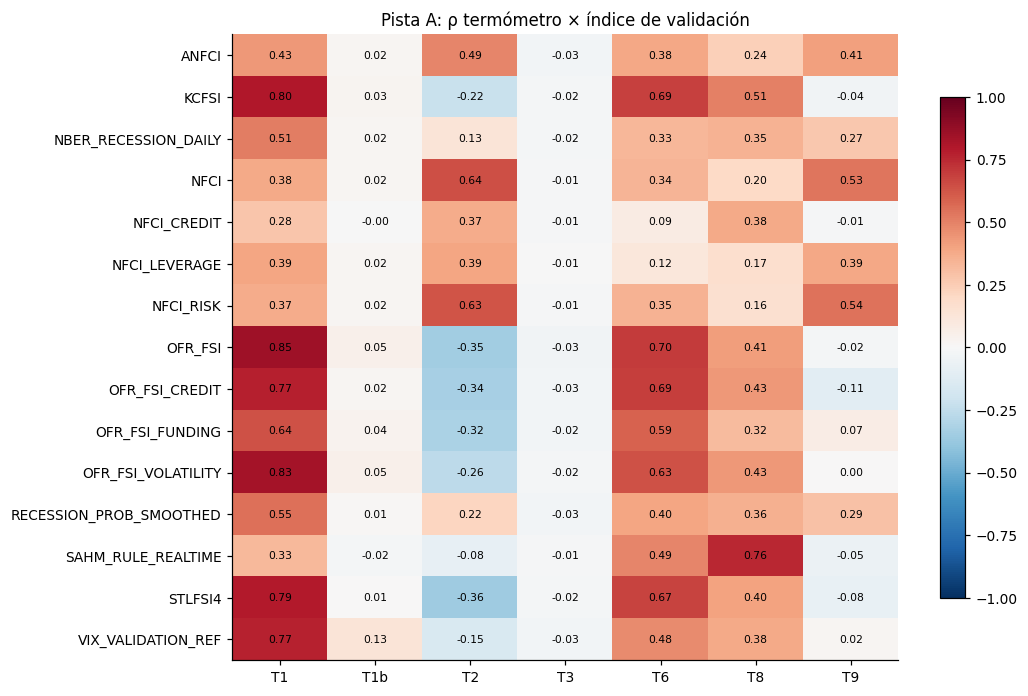

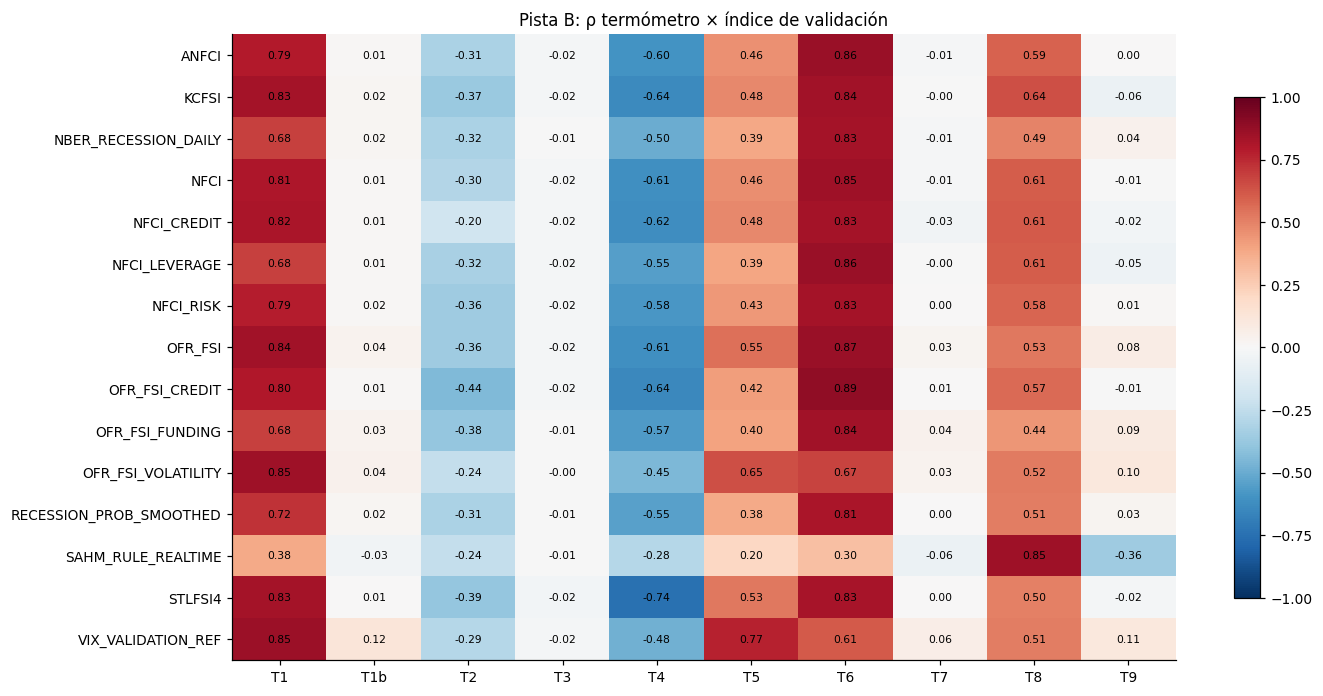

,pista,termometro,referencia,rho,ok_alguna
0,A,T1_renta_variable,STLFSI4,0.794,True
1,A,T1_renta_variable,VIX_VALIDATION_REF,0.769,True
2,A,T6_credito,NFCI_CREDIT,0.085,True
3,A,T6_credito,OFR_FSI_CREDIT,0.688,True
4,A,T8_actividad,SAHM_RULE_REALTIME,0.757,True
5,A,T8_actividad,RECESSION_PROB_SMOOTHED,0.359,True
6,B,T1_renta_variable,STLFSI4,0.829,True
7,B,T1_renta_variable,VIX_VALIDATION_REF,0.853,True
8,B,T5_vol_implicita,OFR_FSI_VOLATILITY,0.646,True
9,B,T5_vol_implicita,VIX_VALIDATION_REF,0.770,True


In [13]:
CORR = {}
for pista in ('A', 'B'):
    T = TERM[pista]
    V = pd.DataFrame({n: alinear(s, T.index) for n, s in VALIDACION.items()})
    CORR[pista] = pd.DataFrame({v: T.corrwith(V[v]) for v in V.columns}).T
    fig, ax = plt.subplots(figsize=(1.05 * T.shape[1] + 2.5, .36 * len(V.columns) + 1))
    im = ax.imshow(CORR[pista].values, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
    ax.set_xticks(range(T.shape[1]), [c.split('_', 1)[0] for c in T.columns])
    ax.set_yticks(range(len(V.columns)), V.columns)
    for i in range(CORR[pista].shape[0]):
        for j in range(CORR[pista].shape[1]):
            ax.text(j, i, f'{CORR[pista].iat[i, j]:.2f}', ha='center', va='center', fontsize=7)
    fig.colorbar(im, ax=ax, shrink=.8); ax.set_title(f'Pista {pista}: ρ termómetro × índice de validación')
    ax.grid(False); plt.tight_layout(); plt.show()

REF = {'T1_renta_variable': ['STLFSI4', 'VIX_VALIDATION_REF'],
       'T5_vol_implicita': ['OFR_FSI_VOLATILITY', 'VIX_VALIDATION_REF'],
       'T6_credito': ['NFCI_CREDIT', 'OFR_FSI_CREDIT'],
       'T8_actividad': ['SAHM_RULE_REALTIME', 'RECESSION_PROB_SMOOTHED']}
filas = []
for pista in ('A', 'B'):
    for t, refs in REF.items():
        if t not in CORR[pista].columns:
            continue
        for r in refs:
            filas.append({'pista': pista, 'termometro': t, 'referencia': r, 'rho': CORR[pista].loc[r, t]})
val3 = pd.DataFrame(filas)
val3['ok_alguna'] = val3.groupby(['pista', 'termometro'])['rho'].transform(lambda s: (s.abs() >= .3).any())
display(val3.round(3))

## 10. Validación 4 · relevancia frente a las crisis

Primera vez que los termómetros se cruzan con las crisis, **después de congelar el ADR-008**. Cada termómetro
se usa solo, como regla de umbral: marca crisis si supera su percentil 90 de lo visto hasta ayer (la misma
regla que `VOL_P90`, fijada antes de ver los resultados). Se evalúa en el OOS de cada pista con la detección
por evento de ADR-003 y se compara con `persistent_random_null`: una señal de Markov independiente de las
crisis con la misma tasa y persistencia.

`p_null` tiene una resolución de 1/300 y hay 17 comparaciones: los valores cercanos a 0,003 no son concluyentes
por sí solos. También se muestra qué fracción de cada crisis y de cada trampa marca cada termómetro.

In [14]:
from regimenes.benchmark.ejecucion import DEFAULT_TRAIN_DAYS
from regimenes.evaluacion import ranking as rk
from regimenes.evaluacion.metricas import detection_summary, event_detection_table

TRAMPAS = {k: tuple(v['ventana']) for k, v in BENCH['false_positive_windows'].items()
           if isinstance(v, dict) and v.get('en_catalogo') is False and 'ventana' in v}


def racha_media(f):
    d = np.diff(np.r_[0, f.to_numpy().astype(int), 0])
    largos = np.flatnonzero(d == -1) - np.flatnonzero(d == 1)
    return float(largos.mean()) if len(largos) else 1.0


def evalua_regla(flags, ventanas):
    s = detection_summary(flags, ventanas)
    score = rk.detection_score(s['det_precision'], s['det_event_recall'])
    nula = rk.persistent_random_null(flags.index, ventanas, rate=float(flags.mean()),
                                     mean_run=racha_media(flags), n_sims=300)
    return {'score': score, 'p_null': float((nula['score_deteccion'] >= score).mean()),
            'detectadas': f"{int(s['det_n_detectados'])}/{int(s['det_n_eventos'])}",
            'precision': s['det_precision'], 'lift': s['det_lift_precision'], 'marcado': float(flags.mean())}


T_OFICIAL, OOS, filas, sensibilidad, MAPA = {}, {}, [], [], {}
for pista in ('B', 'A'):
    T_OFICIAL[pista], _ = ft.termometros_pista(CRUDO[pista][0], pista)
    T = T_OFICIAL[pista]
    OOS[pista] = T.dropna().index[DEFAULT_TRAIN_DAYS[pista]:]
    ventanas = rk.track_crisis_windows(pista)
    cobertura = {}
    for t in T.columns:
        s = T[t].dropna()
        marca = (s > rk.expanding_quantile_causal(s, 0.9, min_obs=252)).reindex(OOS[pista]).fillna(False).astype(bool)
        tabla = event_detection_table(marca, ventanas)
        cobertura[t.split('_')[0]] = (tabla['dias_marcados'] / tabla['dias_oos']).where(tabla['dias_oos'] > 0)
        filas.append({'pista': pista, 'termometro': t, **evalua_regla(marca, ventanas),
                      **{k: float(marca.loc[a:z].mean()) for k, (a, z) in TRAMPAS.items() if len(marca.loc[a:z])}})
        # Sensibilidad exploratoria (no pre-registrada): percentil 90 móvil de 5 años.
        movil = s.shift(1).rolling(1260, min_periods=252).quantile(0.9)
        marca_m = (s > movil).reindex(OOS[pista]).fillna(False).astype(bool)
        sensibilidad.append({'pista': pista, 'termometro': t, **evalua_regla(marca_m, ventanas)})
    MAPA[pista] = pd.DataFrame(cobertura).dropna(how='all')
relevancia = pd.DataFrame(filas)
display(relevancia.round(3))
for pista, m in MAPA.items():
    print(f'Pista {pista}: fracción de días marcados dentro de cada crisis')
    display(m.round(2))

,pista,termometro,score,p_null,detectadas,precision,lift,marcado,taper_2013,debtceiling_2013
0,B,T1_renta_variable,0.291,0.197,2/9,0.422,2.442,0.041,0.000,0.0
1,B,T1b_rentabilidad_diaria,0.365,0.000,3/9,0.402,2.329,0.068,0.000,0.0
2,B,T2_tipos_nivel_curva,0.247,0.563,5/9,0.159,0.921,0.352,0.000,0.0
3,B,T3_velocidad_tipos,0.307,0.000,3/9,0.284,1.645,0.085,0.179,0.0
4,B,T4_inflacion_tipo_real,0.353,0.113,5/9,0.259,1.499,0.202,0.000,0.0
5,B,T5_vol_implicita,0.595,0.000,6/9,0.538,3.115,0.081,0.000,0.0
6,B,T6_credito,0.000,1.000,0/9,NaN,NaN,0.000,0.000,0.0
7,B,T7_divisas_materias_primas,0.261,0.003,2/9,0.315,1.823,0.071,0.032,0.0
8,B,T8_actividad,0.000,1.000,0/9,0.000,0.000,0.026,0.000,0.0
9,B,T9_inflacion_valoracion,0.180,0.247,1/9,0.468,2.709,0.103,0.000,0.0


Pista B: fracción de días marcados dentro de cada crisis


,T1,T1b,T2,T3,T4,T5,T6,T7,T8,T9
crisis,,,,,,,,,,
flash_crash_euro1_2010,0.00,0.02,0.00,0.02,0.24,0.02,0.0,0.12,0.0,0.0
us_downgrade_euro2_2011,0.00,0.07,0.00,0.05,0.25,0.03,0.0,0.14,0.0,0.0
china_oil_2015_16,0.00,0.09,0.28,0.08,0.00,0.02,0.0,0.05,0.0,0.0
volmageddon_2018q1,0.00,0.20,1.00,0.20,0.00,0.40,0.0,0.20,0.0,0.0
fed_tightening_2018q4,0.02,0.15,1.00,0.03,0.00,0.23,0.0,0.08,0.0,0.0
covid_2020,0.50,0.58,0.00,0.21,0.00,0.88,0.0,0.33,0.0,0.0
inflation_bear_2022,0.27,0.24,0.37,0.29,0.83,0.62,0.0,0.19,0.0,1.0
svb_banking_2023,0.07,0.22,1.00,0.22,0.26,0.07,0.0,0.19,0.0,0.0
tariff_selloff_2025,0.09,0.17,0.00,0.14,0.11,0.20,0.0,0.11,0.0,0.0


Pista A: fracción de días marcados dentro de cada crisis


,T1,T1b,T2,T3,T6,T8,T9
crisis,,,,,,,
bear_1969_70,1.00,0.73,0.00,0.45,0.00,1.00,0.00
oil_stagflation_1973,0.54,0.31,0.00,0.07,0.00,0.00,0.62
volcker_1980_82,0.16,0.17,0.24,0.23,0.05,0.00,0.00
black_monday_1987,0.47,0.36,0.00,0.08,0.00,0.00,0.00
gulf_war_sl_1990,0.35,0.37,0.00,0.06,0.00,0.00,0.00
ltcm_russia_1998,0.03,0.41,0.00,0.00,0.00,0.00,0.00
dotcom_2000_02,0.68,0.27,0.00,0.06,0.00,0.26,0.00
gfc_2007_09,0.59,0.31,0.00,0.15,0.31,0.37,0.00
flash_crash_euro1_2010,0.00,0.32,0.00,0.06,0.00,0.00,0.00


### 10.1 Sensibilidad exploratoria: percentil móvil de 5 años

T6 no marca ningún día en B con la regla principal: el percentil expansivo arranca en 2007 y queda fijado por
la crisis de 2008. Por eso se repite con un percentil móvil de 5 años. **No está pre-registrado:** solo sirve
para separar el efecto de la regla del contenido del termómetro y no sustituye a la tabla anterior.

In [15]:
display(pd.DataFrame(sensibilidad).round(3))

,pista,termometro,score,p_null,detectadas,precision,lift,marcado
0,B,T1_renta_variable,0.466,0.000,4/9,0.490,2.839,0.102
1,B,T1b_rentabilidad_diaria,0.456,0.000,5/9,0.387,2.240,0.090
2,B,T2_tipos_nivel_curva,0.299,0.330,5/9,0.204,1.182,0.403
3,B,T3_velocidad_tipos,0.307,0.000,3/9,0.284,1.644,0.096
4,B,T4_inflacion_tipo_real,0.319,0.220,5/9,0.224,1.297,0.194
5,B,T5_vol_implicita,0.549,0.000,6/9,0.467,2.704,0.116
6,B,T6_credito,0.332,0.107,2/9,0.659,3.816,0.065
7,B,T7_divisas_materias_primas,0.254,0.007,2/9,0.297,1.719,0.092
8,B,T8_actividad,0.098,0.550,1/9,0.088,0.511,0.050
9,B,T9_inflacion_valoracion,0.289,0.207,3/9,0.256,1.480,0.152


## 11. Valor añadido en los detectores: menú N frente a menú T (prueba de humo)

Mismo detector, mismas fechas y mismos hiperparámetros: solo cambian las columnas de entrada. Los resultados
salen de `python -m regimenes.benchmark.variantes` (`results/detectores/menus_humo/`), que este notebook solo
lee. Se ejecutaron los detectores rápidos; faltan D04 y D09 en las dos pistas, y D08 y D10 en la A. El menú N
se contrasta con el `ranking_v2.csv` oficial. El menú T de este portátil no lleva `CAPE_z`, `FF_RMW_z` ni
`FF_industry_dispersion_z`, que el núcleo N no usa.

In [16]:
humo = pd.concat([pd.read_csv(p) for p in sorted((rutas.RESULTS_DETECTORES / 'menus_humo').glob('*.csv'))])
oficial = pd.read_csv(rutas.RESULTS_BENCHMARK / 'ranking_v2.csv').set_index(['pista', 'id'])['score_deteccion']
tabla = humo.pivot(index=['pista', 'base'], columns='menu', values='score_deteccion')
tabla['diferencia'] = tabla['T'] - tabla['N']
tabla['N_oficial'] = [oficial[i] for i in tabla.index]
crisis = humo.assign(c=humo['det_n_detectados'].astype(int).astype(str) + '/' + humo['det_n_eventos'].astype(int).astype(str))
tabla = tabla.join(crisis.pivot(index=['pista', 'base'], columns='menu', values='c').add_prefix('crisis_'))
display(tabla.round(3))
assert (tabla['N'] - tabla['N_oficial']).abs().max() < 5e-4, 'el menú N no reproduce el ranking oficial'
assert humo.groupby('pista')['n_oos'].nunique().eq(1).all(), 'N y T no comparten fechas OOS'
print('Mejoran con T:', tabla.groupby('pista')['diferencia'].apply(lambda d: f'{int((d > 0).sum())} de {len(d)}').to_dict())

menu            N      T  diferencia  N_oficial crisis_N crisis_T
pista base                                                       
A     D02   0.559  0.537      -0.022      0.559    12/17    10/17
      D03   0.565  0.384      -0.181      0.565    15/17    11/17
B     D02   0.501  0.459      -0.043      0.501      6/9      6/9
      D03   0.241  0.166      -0.075      0.241      2/9      2/9
      D08   0.274  0.000      -0.274      0.274      3/9      0/9
      D10   0.457  0.477       0.020      0.457      9/9      7/9

Mejoran con T: {'A': '0 de 2', 'B': '1 de 4'}


## 12. Conclusiones y pendientes

Decisiones tomadas **sin etiquetas de crisis**, congeladas en el ADR-008 antes de las secciones 10 y 11:

1. **Reparto en bloques (sección 4):** 10 bloques en B y 7 en A. T1 se separa en estado (T1) y rentabilidad
   diaria (T1b); la macro se separa en actividad (T8) e inflación realizada + valoración (T9, ancla PPI).
   Ancla de T2: el tipo corto (sección 4.3).
2. **Umbral (sección 5):** 30 %. No se activa con el reparto final; queda como red de seguridad.
3. **Calentamiento (sección 6):** toda la historia anterior a la ventana.

**Como medidores, los termómetros funcionan** (validaciones 1 a 3, secciones 2, 8 y 9).

**Como alarma, solo algunos (sección 10).** T5 es el mejor (0,595 y 6/9 en B), y T1 y T1b dan señal en A (0,559
y 0,516). T3 es el que más marca el *taper* de 2013 (18 % de sus días en B, unas 2 veces su tasa normal), mientras
crédito, volatilidad e inflación marcan 0: apoya que fue estrés de tipos, con una señal moderada. T6 y T8 no
sirven como alarma en B (0/9). En T6 influye la regla: con percentil móvil (exploratorio) llega a 2/9 con lift
3,8, pero sigue perdiendo la mayoría. T8 sigue en 1/9.

**En los detectores, el menú T empeora en 5 de 6 casos (sección 11).** Solo D10 en B sube (+0,020), y detecta 2
crisis menos. Con los criterios del ADR-008 §6, ya no puede mejorar la mayoría en B: empeoran 3 de 6. Apunta a
«con el pool completo, lo simple sigue ganando». Una hipótesis, sin probar, es que comprimir diluye la señal
rápida de volatilidad entre bloques lentos.

**No es definitivo:** es una prueba de humo sin 3 columnas en el menú T, faltan D04 y D09 en las dos pistas y D08
y D10 en la A, y no hay MCS sobre estas diferencias. Bloques y anclas **no** se retocan a la vista de estos
resultados: cualquier variante se declara como exploratoria en el ADR-008.

Pendiente para la versión oficial (portátil principal):

1. Repetir sobre los datos verificados con los sha256 de `03_preprocesado`, con las 3 columnas que faltan, y
   guardar los termómetros con `escribir_termometros`.
2. Ejecutar las combinaciones que faltan y el MCS dentro de cada menú con bootstrap por bloques de días.